# Notebook 01: Data Quality Audit, Cleaning & Exploratory Data Analysis (EDA)

**Project:** Development of an AI/ML Model for Identifying Patterns in Road Traffic Accidents  
**Phase:** CRISP-DM Phase 2 & 3 — Data Understanding and Initial Data Preparation  

### Purpose of This Notebook
Before training any machine learning model, we need to understand the Addis Ababa Road Traffic Accident dataset (`RTA Dataset.csv`), check its quality, remove post-crash data leakage, clean formatting errors, and explore how driver, vehicle, road, and environmental factors relate to crash severity.

Specifically, this notebook covers:
1. **Schema & Target Audit**: Confirming record counts, data types, duplicates, and exact class imbalance (`Slight`, `Serious`, `Fatal`).
2. **Leakage Removal**: Dropping casualty columns recorded *after* the crash outcome.
3. **Missing-Value & Text Cleaning**: Fixing corrupted text labels and handling columns with >30% missing values safely.
4. **Crash Event Grouping**: Detecting multi-vehicle records from the same crash so train and test sets never share the same accident event.
5. **Exploratory Visualizations & Chi-Square ($\chi^2$) Statistical Tests**: Visualizing key risk patterns and statistically testing which features are associated with crash severity.

## 1. Environment Setup & Library Imports
First, we import our data analysis, plotting, and statistical libraries, along with our shared project helper module (`src/utils.py`).

In [1]:
import os
import sys
from pathlib import Path

# Keep Matplotlib cache inside /tmp to avoid permission warnings
os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

# Add the project root folder to sys.path so we can import src/utils.py
PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.utils import (
    CASUALTY_LEAKAGE_COLS,
    SEVERITY_ORDER,
    TARGET_COL,
    assign_crash_event_id,
    clean_rta_data,
)

# Set a clean, consistent visual theme for all thesis figures
sns.set_theme(style="whitegrid", palette="deep", font_scale=1.05)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300

FIG_DIR = PROJECT_ROOT / "outputs" / "figures"
TAB_DIR = PROJECT_ROOT / "outputs" / "tables"
PROC_DIR = PROJECT_ROOT / "data" / "processed"
for folder in [FIG_DIR, TAB_DIR, PROC_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)

Project root: /Users/israel/Documents/Projects/accident_severity_model_prediction


**Setup Interpretation:**  
All required packages and output folders (`outputs/figures/`, `outputs/tables/`, and `data/processed/`) are configured so that every chart and summary table generated in this notebook is saved automatically for Chapter 4 of the project report.

---
## 2. Load Raw Dataset & Check Basic Integrity
Next, we load `RTA Dataset.csv` and run basic integrity checks: row/column dimensions, exact duplicate rows, missing target values, and the exact distribution of `Accident_severity`.

In [2]:
# Load the raw Addis Ababa road traffic accident dataset
raw_path = PROJECT_ROOT / "RTA Dataset.csv"
df_raw = pd.read_csv(raw_path)

# Basic integrity checks
print(f"Dataset shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
print(f"Exact duplicate rows: {df_raw.duplicated().sum()}")
print(f"Missing values in target ('{TARGET_COL}'): {df_raw[TARGET_COL].isna().sum()}")

# Summarize target class counts and percentages
target_summary = pd.DataFrame({
    "Count": df_raw[TARGET_COL].value_counts().reindex(SEVERITY_ORDER),
    "Percentage (%)": (df_raw[TARGET_COL].value_counts(normalize=True).reindex(SEVERITY_ORDER) * 100).round(2),
})
imbalance_ratio = target_summary.loc["Slight Injury", "Count"] / target_summary.loc["Fatal injury", "Count"]
print(f"Imbalance ratio (Slight : Fatal) = {imbalance_ratio:.1f} : 1\n")
display(target_summary)

Dataset shape: 12,316 rows x 32 columns
Exact duplicate rows: 0
Missing values in target ('Accident_severity'): 0
Imbalance ratio (Slight : Fatal) = 65.9 : 1



,Count,Percentage (%)
Accident_severity,,
Slight Injury,10415,84.56
Serious Injury,1743,14.15
Fatal injury,158,1.28


**Integrity & Class Distribution Findings:**  
- The dataset contains **12,316 crash records and 32 attributes**, with **0 duplicate rows** and **0 missing target labels**, matching Section 3.2 of the methodology.
- The target variable is heavily imbalanced:
  - **Slight Injury**: 10,415 records (**84.56%**)
  - **Serious Injury**: 1,743 records (**14.15%**)
  - **Fatal injury**: 158 records (**1.28%**) — roughly **1 fatal record for every 66 slight injury records**.
- Because a naive model predicting *"Slight Injury"* for every crash would achieve **84.56% accuracy** while catching **0%** of fatal or serious crashes, overall accuracy is misleading and **Macro-F1, minority-class Recall, and ROC-AUC** must guide model selection.

---
## 3. Visualizing Target Class Imbalance
We plot both the primary **3-class target** (`Slight`, `Serious`, `Fatal`) and the **binary fallback target** (`Serious/Fatal` combined vs. `Slight`, noted in Section 3.2.4) to clearly illustrate the class distribution.

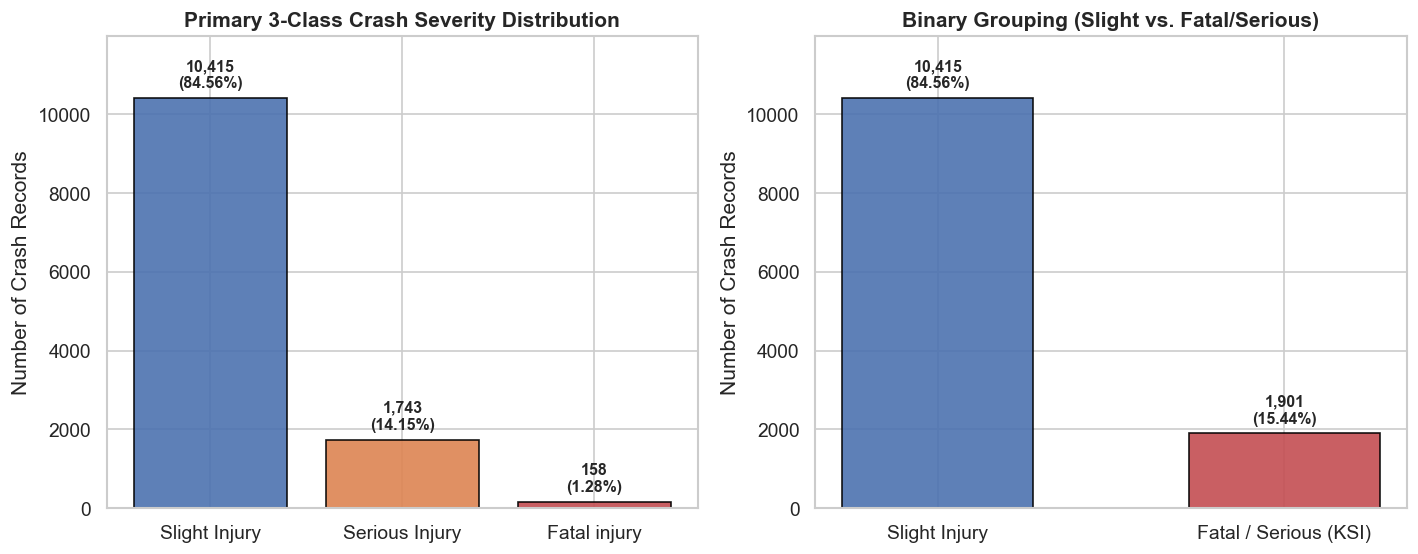

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

# Left plot: 3-class distribution
colors_3 = ["#4C72B0", "#DD8452", "#C44E52"]
counts_3 = df_raw[TARGET_COL].value_counts().reindex(SEVERITY_ORDER)
bars1 = axes[0].bar(SEVERITY_ORDER, counts_3.values, color=colors_3, edgecolor="black", alpha=0.9)
axes[0].set_title("Primary 3-Class Crash Severity Distribution", fontweight="bold")
axes[0].set_ylabel("Number of Crash Records")
axes[0].set_ylim(0, counts_3.max() * 1.15)

for bar, cnt in zip(bars1, counts_3.values):
    pct = cnt / len(df_raw) * 100
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 180,
        f"{cnt:,}\n({pct:.2f}%)",
        ha="center", va="bottom", fontsize=9.5, fontweight="bold"
    )

# Right plot: Binary fallback (Killed or Seriously Injured [KSI] vs Slight)
ksi_series = np.where(df_raw[TARGET_COL] == "Slight Injury", "Slight Injury", "Fatal / Serious (KSI)")
ksi_order = ["Slight Injury", "Fatal / Serious (KSI)"]
counts_2 = pd.Series(ksi_series).value_counts().reindex(ksi_order)
bars2 = axes[1].bar(ksi_order, counts_2.values, color=["#4C72B0", "#C44E52"], edgecolor="black", alpha=0.9, width=0.55)
axes[1].set_title("Binary Grouping (Slight vs. Fatal/Serious)", fontweight="bold")
axes[1].set_ylabel("Number of Crash Records")
axes[1].set_ylim(0, counts_2.max() * 1.15)

for bar, cnt in zip(bars2, counts_2.values):
    pct = cnt / len(df_raw) * 100
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 180,
        f"{cnt:,}\n({pct:.2f}%)",
        ha="center", va="bottom", fontsize=9.5, fontweight="bold"
    )

plt.tight_layout()
plt.savefig(FIG_DIR / "01_target_distribution.png", bbox_inches="tight")
plt.show()

**Chart Interpretation:**  
The left chart highlights the extreme rarity of `Fatal injury` (only 158 cases in the entire dataset—meaning a 15% test split holds ~24 fatal crashes). The right chart shows that combining `Fatal` and `Serious` into a binary **Severe/Fatal (KSI)** indicator yields **1,901 positive cases (15.44%)**, which provides a useful secondary stability benchmark alongside our primary 3-class models in Notebook 03.

---
## 4. Missing-Value Audit (Before Cleaning) & Removing Leakage Columns
Following Section 3.3.1 of the methodology, casualty-level fields (`Number_of_casualties`, `Casualty_class`, `Casualty_severity`, etc.) describe the *outcome* after the crash happens and would leak the answer if used as predictors. Let us inspect missing values across the **24 valid pre-/at-crash predictors** before cleaning.

Excluded post-crash leakage columns (7): ['Number_of_casualties', 'Casualty_class', 'Sex_of_casualty', 'Age_band_of_casualty', 'Casualty_severity', 'Work_of_casuality', 'Fitness_of_casuality']
Remaining pre-/at-crash predictor columns: 24


,Feature,Null_Count,Null_Pct,Explicit_Unknown_Count,Total_Missing_or_Unknown_Pct,Unique_Values
0,Defect_of_vehicle,4427,35.95,0,35.95,3
1,Service_year_of_vehicle,3928,31.89,2883,55.30,6
2,Type_of_vehicle,950,7.71,0,7.71,17
3,Types_of_Junction,887,7.20,191,8.75,8
4,Driving_experience,829,6.73,33,7.00,7
5,Educational_level,741,6.02,100,6.83,7
6,Vehicle_driver_relation,579,4.70,14,4.81,4
7,Owner_of_vehicle,482,3.91,0,3.91,4
8,Lanes_or_Medians,385,3.13,57,3.59,7
9,Vehicle_movement,308,2.50,88,3.22,13


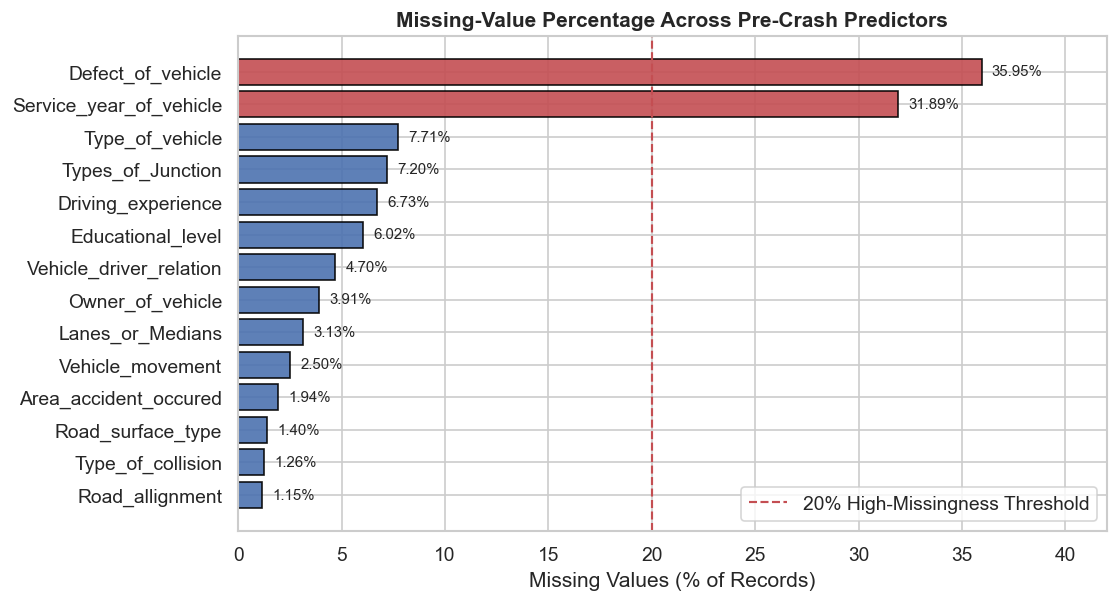

In [4]:
# Separate the 24 valid pre-/at-crash predictors from the 7 casualty leakage columns
predictor_cols_raw = [c for c in df_raw.columns if c not in CASUALTY_LEAKAGE_COLS + [TARGET_COL]]
print(f"Excluded post-crash leakage columns ({len(CASUALTY_LEAKAGE_COLS)}): {CASUALTY_LEAKAGE_COLS}")
print(f"Remaining pre-/at-crash predictor columns: {len(predictor_cols_raw)}")

# Calculate missing counts and percentages (including 'Unknown'/'unknown'/'na' tokens as well as NaN)
missing_rows = []
for col in predictor_cols_raw:
    na_cnt = df_raw[col].isna().sum()
    unk_cnt = df_raw[col].astype(str).str.strip().str.lower().isin(["unknown", "na"]).sum()
    missing_rows.append({
        "Feature": col,
        "Null_Count": na_cnt,
        "Null_Pct": round(na_cnt / len(df_raw) * 100, 2),
        "Explicit_Unknown_Count": unk_cnt,
        "Total_Missing_or_Unknown_Pct": round((na_cnt + unk_cnt) / len(df_raw) * 100, 2),
        "Unique_Values": df_raw[col].nunique(dropna=True),
    })

missing_df = pd.DataFrame(missing_rows).sort_values("Null_Pct", ascending=False).reset_index(drop=True)
missing_df.to_csv(TAB_DIR / "01_missing_values_summary.csv", index=False)
display(missing_df.head(14))

# Plot features that have missing (NaN) values
has_nulls = missing_df[missing_df["Null_Pct"] > 0].sort_values("Null_Pct", ascending=True)
fig, ax = plt.subplots(figsize=(9.5, 5.2))
bars = ax.barh(
    has_nulls["Feature"],
    has_nulls["Null_Pct"],
    color=np.where(has_nulls["Null_Pct"] > 20, "#C44E52", "#4C72B0"),
    edgecolor="black",
    alpha=0.9,
)
ax.axvline(20, color="#C44E52", linestyle="--", linewidth=1.3, label="20% High-Missingness Threshold")
ax.set_xlabel("Missing Values (% of Records)")
ax.set_title("Missing-Value Percentage Across Pre-Crash Predictors", fontweight="bold")
ax.set_xlim(0, 42)
ax.legend(loc="lower right")

for bar, pct in zip(bars, has_nulls["Null_Pct"]):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2, f"{pct:.2f}%", va="center", fontsize=9)

plt.tight_layout()
plt.savefig(FIG_DIR / "01_missing_values.png", bbox_inches="tight")
plt.show()

**Missing-Value Findings & Handling Strategy:**  
- Only **2 predictors** exceed the 20% missingness line: `Defect_of_vehicle` (**35.95% NaN**) and `Service_year_of_vehicle` (**31.89% NaN**, plus another 23.4% already labeled `'Unknown'`).
- Dropping rows with missing values would discard over **40%** of the dataset (including scarce fatal crashes). Conversely, mode-imputing `Defect_of_vehicle` into `'No defect'` would falsely assume 4,427 uninspected vehicles had no defects.
- Therefore, high-missingness columns (`Defect_of_vehicle` and `Service_year_of_vehicle`) are safely assigned an explicit **`'Unknown'`** category, while low-missingness columns (`<8%` missing, such as `Type_of_vehicle` at 7.71% and `Types_of_Junction` at 7.20%) will be imputed inside each training fold during modeling.

---
## 5. Cleaning Text Formatting & Assigning Crash Event IDs
Inspection of raw string categories reveals minor data-entry issues in `RTA Dataset.csv` (for example, `'  Recreational areas'` with leading spaces, `'Lorry (41?100Q)'` with `?` instead of `-`, and `'statioNot a Pedestrianry'` caused by an earlier find-and-replace glitch on `'na'`).

In addition, we check whether multiple rows share the exact same `(Time, Day_of_week)`—indicating multiple vehicles/drivers from the **same crash event**—and assign a `crash_event_id` so those rows are never split across training and testing sets.

In [5]:
# Apply our clean_rta_data() helper to drop casualty leakage columns and fix string glitches
df_clean = clean_rta_data(df_raw, drop_leakage=True)

# Verify text repairs on sample columns
print("Cleaned 'Type_of_vehicle' sample values:")
print([v for v in df_clean["Type_of_vehicle"].dropna().unique() if "Lorry" in v or "Public" in v])

print("\nCleaned 'Pedestrian_movement' sample values:")
print([v for v in df_clean["Pedestrian_movement"].dropna().unique() if "stationary" in v][:2])

# Assign crash_event_id based on shared (Day_of_week, Time)
df_clean["crash_event_id"] = assign_crash_event_id(df_clean)

# Evaluate multi-row crash event statistics
n_events = df_clean["crash_event_id"].nunique()
adjacent_same = (
    (df_clean["Time"] == df_clean["Time"].shift(1))
    & (df_clean["Day_of_week"] == df_clean["Day_of_week"].shift(1))
)
adj_same_sev = (adjacent_same & (df_clean[TARGET_COL] == df_clean[TARGET_COL].shift(1))).sum()

print(f"\nTotal rows: {len(df_clean):,} | Distinct (Day, Time) crash groups: {n_events:,}")
print(f"Adjacent rows sharing exact (Day, Time): {adjacent_same.sum():,} ({adjacent_same.mean()*100:.1f}% of dataset)")
print(f"Severity agreement across adjacent same-time rows: {adj_same_sev / adjacent_same.sum() * 100:.2f}%")

# Sanity check: confirm zero casualty leakage columns remain
assert not any(c in df_clean.columns for c in CASUALTY_LEAKAGE_COLS), "Leakage column still present!"
print("Verification passed: 0 post-crash casualty columns remain.")

Cleaned 'Type_of_vehicle' sample values:
['Public (> 45 seats)', 'Lorry (41-100Q)', 'Public (13-45 seats)', 'Lorry (11-40Q)', 'Public (12 seats)']

Cleaned 'Pedestrian_movement' sample values:
['Crossing from nearside - masked by parked or stationary vehicle', 'Crossing from offside - masked by parked or stationary vehicle']

Total rows: 12,316 | Distinct (Day, Time) crash groups: 2,755
Adjacent rows sharing exact (Day, Time): 6,221 (50.5% of dataset)
Severity agreement across adjacent same-time rows: 97.69%
Verification passed: 0 post-crash casualty columns remain.


**Cleaning & Event-Grouping Verification:**  
- Corrupted strings (`Lorry (41-100Q)`, `Public (13-45 seats)`, `stationary`) and whitespace inconsistencies have been repaired cleanly.
- **50.5% of records (6,221 rows)** appear immediately adjacent to another record with the exact same `(Day_of_week, Time)`, and **97.7%** of those pairs share the exact same `Accident_severity`. Grouping by `crash_event_id` during data splitting in Notebook 02 will prevent multi-vehicle records of the same crash from leaking between Train and Test sets (fulfilling Section 3.3.2).

---
## 6. Exploratory Visualizations of Crash Risk Factors

### 6.1 Temporal Risk Patterns: Day of Week & Hour of Day
We examine *when* crashes happen most frequently versus *when* crashes are most likely to be **Serious or Fatal**.

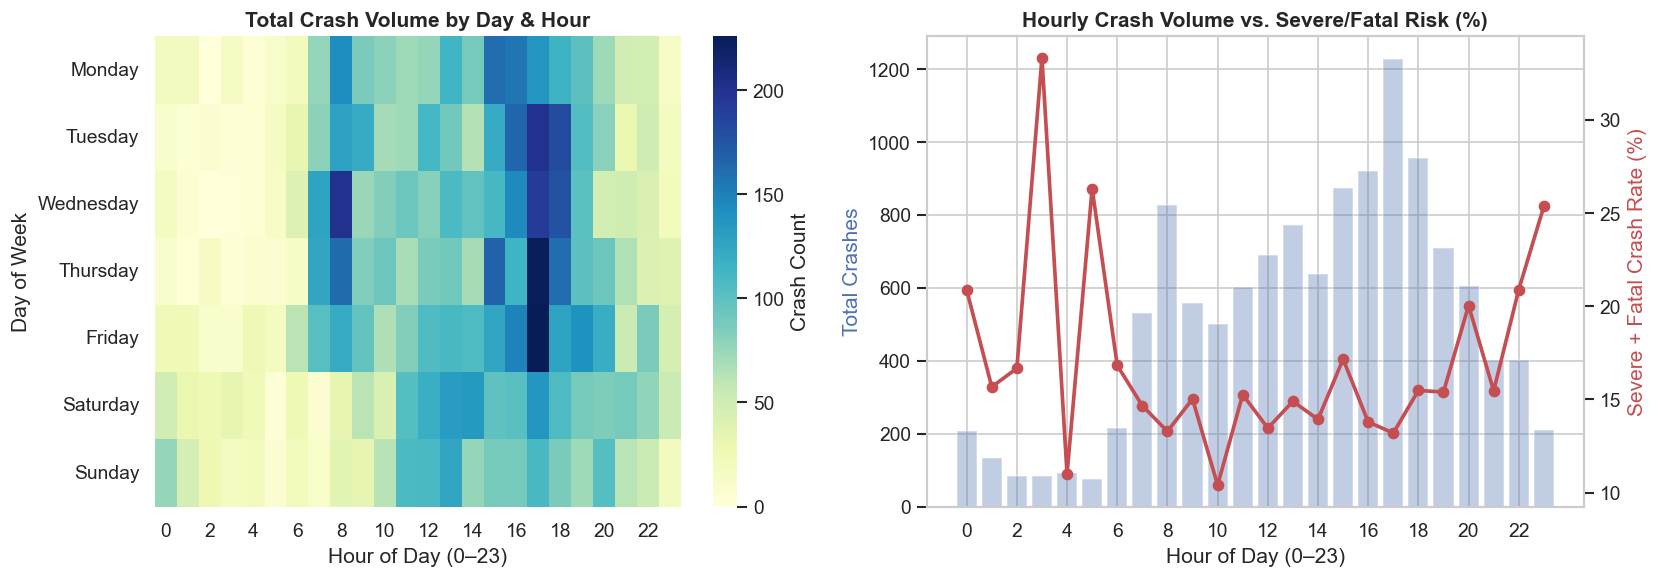

In [6]:
# Parse hour of day (0-23) temporarily for exploratory analysis
eda_df = df_clean.copy()
eda_df["Hour"] = pd.to_datetime(eda_df["Time"], format="%H:%M:%S", errors="coerce").dt.hour
eda_df["Is_Severe_or_Fatal"] = (eda_df[TARGET_COL] != "Slight Injury").astype(int)

day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.0))

# Left: Heatmap of crash counts by Day of Week x Hour
pivot_cnt = eda_df.pivot_table(
    index="Day_of_week", columns="Hour", values=TARGET_COL, aggfunc="count", fill_value=0
).reindex(day_order)
sns.heatmap(pivot_cnt, cmap="YlGnBu", ax=axes[0], cbar_kws={"label": "Crash Count"})
axes[0].set_title("Total Crash Volume by Day & Hour", fontweight="bold")
axes[0].set_xlabel("Hour of Day (0–23)")
axes[0].set_ylabel("Day of Week")

# Right: Hourly crash volume vs. Severe/Fatal crash percentage
hourly = eda_df.groupby("Hour").agg(
    Total_Crashes=(TARGET_COL, "count"),
    Severe_Fatal_Pct=("Is_Severe_or_Fatal", lambda s: s.mean() * 100),
)
ax2 = axes[1]
ax2.bar(hourly.index, hourly["Total_Crashes"], color="#4C72B0", alpha=0.35, label="Total Crashes (left axis)")
ax2.set_xlabel("Hour of Day (0–23)")
ax2.set_ylabel("Total Crashes", color="#4C72B0")
ax2.set_xticks(range(0, 24, 2))

ax2_twin = ax2.twinx()
ax2_twin.plot(
    hourly.index, hourly["Severe_Fatal_Pct"],
    color="#C44E52", marker="o", linewidth=2.2, label="Severe/Fatal Rate % (right axis)"
)
ax2_twin.set_ylabel("Severe + Fatal Crash Rate (%)", color="#C44E52")
ax2_twin.grid(False)
ax2.set_title("Hourly Crash Volume vs. Severe/Fatal Risk (%)", fontweight="bold")

plt.tight_layout()
plt.savefig(FIG_DIR / "01_temporal_heatmap.png", bbox_inches="tight")
plt.show()

**Temporal Pattern Insights:**  
- **Crash Volume**: Most crashes occur during daytime commuting hours—peaking sharply around the **morning rush (07:00–09:00)** and **evening rush (16:00–19:00)** across weekdays.
- **Severity Risk**: Even though fewer total crashes happen late at night, the **proportion of crashes resulting in Serious or Fatal injury rises noticeably during night and early-morning hours (20:00–05:00)**, consistent with higher speeds, lower visibility, and driver fatigue. This confirms why `Hour`, `Time_of_day`, and `Is_rush_hour` are valuable engineered features.

---
### 6.2 Environmental & Road Conditions (`Light_conditions`, `Weather_conditions`, `Road_surface_conditions`)
Next, we visualize how lighting, weather, and road surface conditions affect the rate of **Serious and Fatal** outcomes.

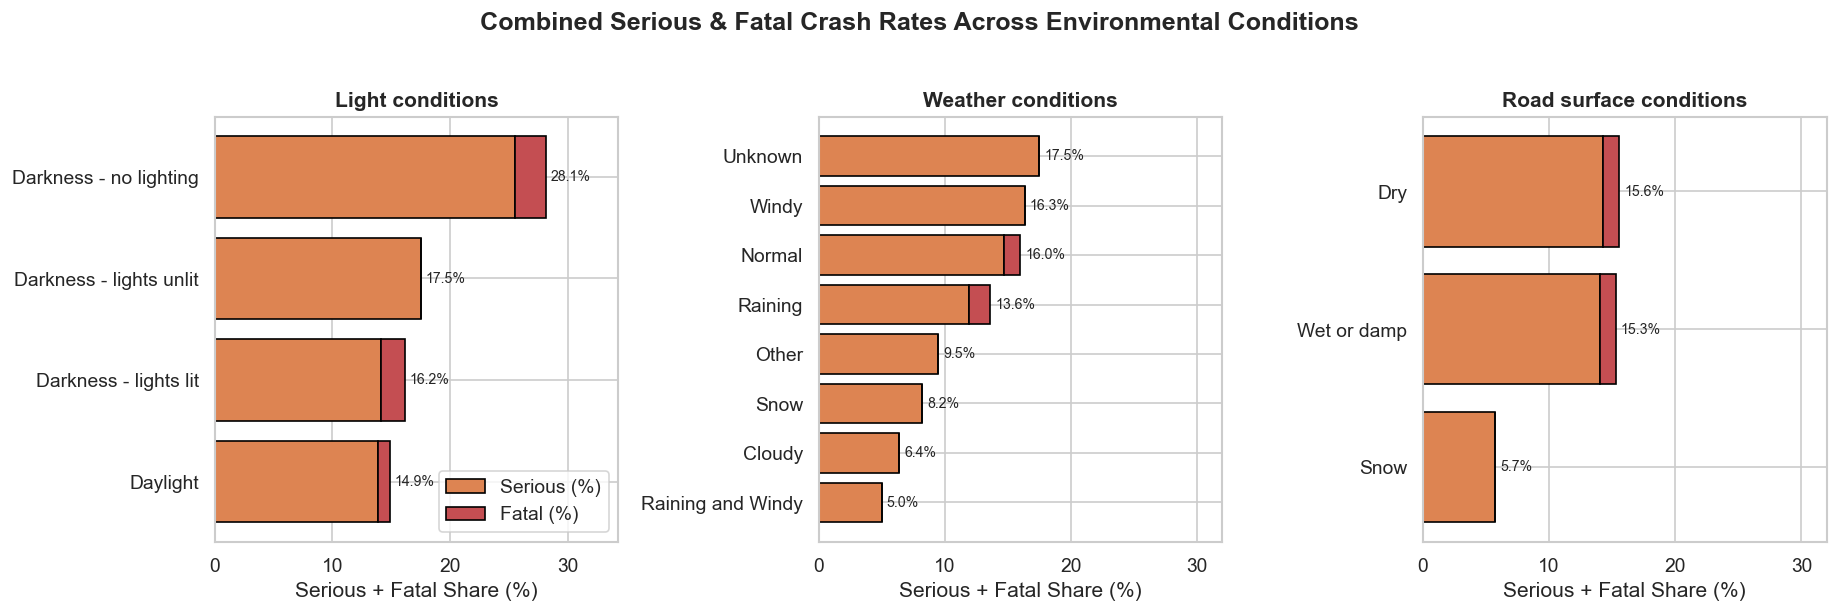

In [7]:
env_cols = ["Light_conditions", "Weather_conditions", "Road_surface_conditions"]
fig, axes = plt.subplots(1, 3, figsize=(15.5, 5.0))

for ax, col in zip(axes, env_cols):
    # Compute percentage of Slight, Serious, and Fatal within each category (for categories with >= 25 records)
    ct = pd.crosstab(eda_df[col], eda_df[TARGET_COL])[SEVERITY_ORDER]
    ct = ct[ct.sum(axis=1) >= 25]
    ct_pct = ct.div(ct.sum(axis=1), axis=0) * 100
    # Sort by combined Serious + Fatal rate
    ct_pct["Severe_Plus_Fatal"] = ct_pct["Serious Injury"] + ct_pct["Fatal injury"]
    ct_pct = ct_pct.sort_values("Severe_Plus_Fatal", ascending=True)

    # Plot Serious and Fatal stacked horizontal bars for clarity
    ax.barh(ct_pct.index, ct_pct["Serious Injury"], color="#DD8452", edgecolor="black", label="Serious (%)")
    ax.barh(
        ct_pct.index, ct_pct["Fatal injury"],
        left=ct_pct["Serious Injury"], color="#C44E52", edgecolor="black", label="Fatal (%)"
    )
    ax.set_title(col.replace("_", " "), fontweight="bold")
    ax.set_xlabel("Serious + Fatal Share (%)")
    ax.set_xlim(0, max(32, ct_pct["Severe_Plus_Fatal"].max() * 1.22))

    for idx_pos, (_, row) in enumerate(ct_pct.iterrows()):
        total_sf = row["Severe_Plus_Fatal"]
        ax.text(total_sf + 0.4, idx_pos, f"{total_sf:.1f}%", va="center", fontsize=8.5)

axes[0].legend(loc="lower right")
plt.suptitle("Combined Serious & Fatal Crash Rates Across Environmental Conditions", fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "01_environmental_severity.png", bbox_inches="tight")
plt.show()

**Environmental Risk Insights:**  
- **Lighting**: Crashes in **`Darkness - no lighting`** exhibit a substantially higher combined Serious + Fatal rate than crashes in `Daylight` or `Darkness - lights lit`, underscoring unlit roads as a critical severity amplifier.
- **Weather & Surface**: While most Addis Ababa crashes happen in `Normal` / `Dry` weather, specific adverse conditions show distinct shifts in severe injury proportions.

---
### 6.3 Crash Circumstances (`Types_of_Junction`, `Type_of_collision`, `Number_of_vehicles_involved`, `Cause_of_accident`)
We now inspect how junction geometry, collision mechanics, vehicle count, and recorded crash causes relate to severe outcomes.

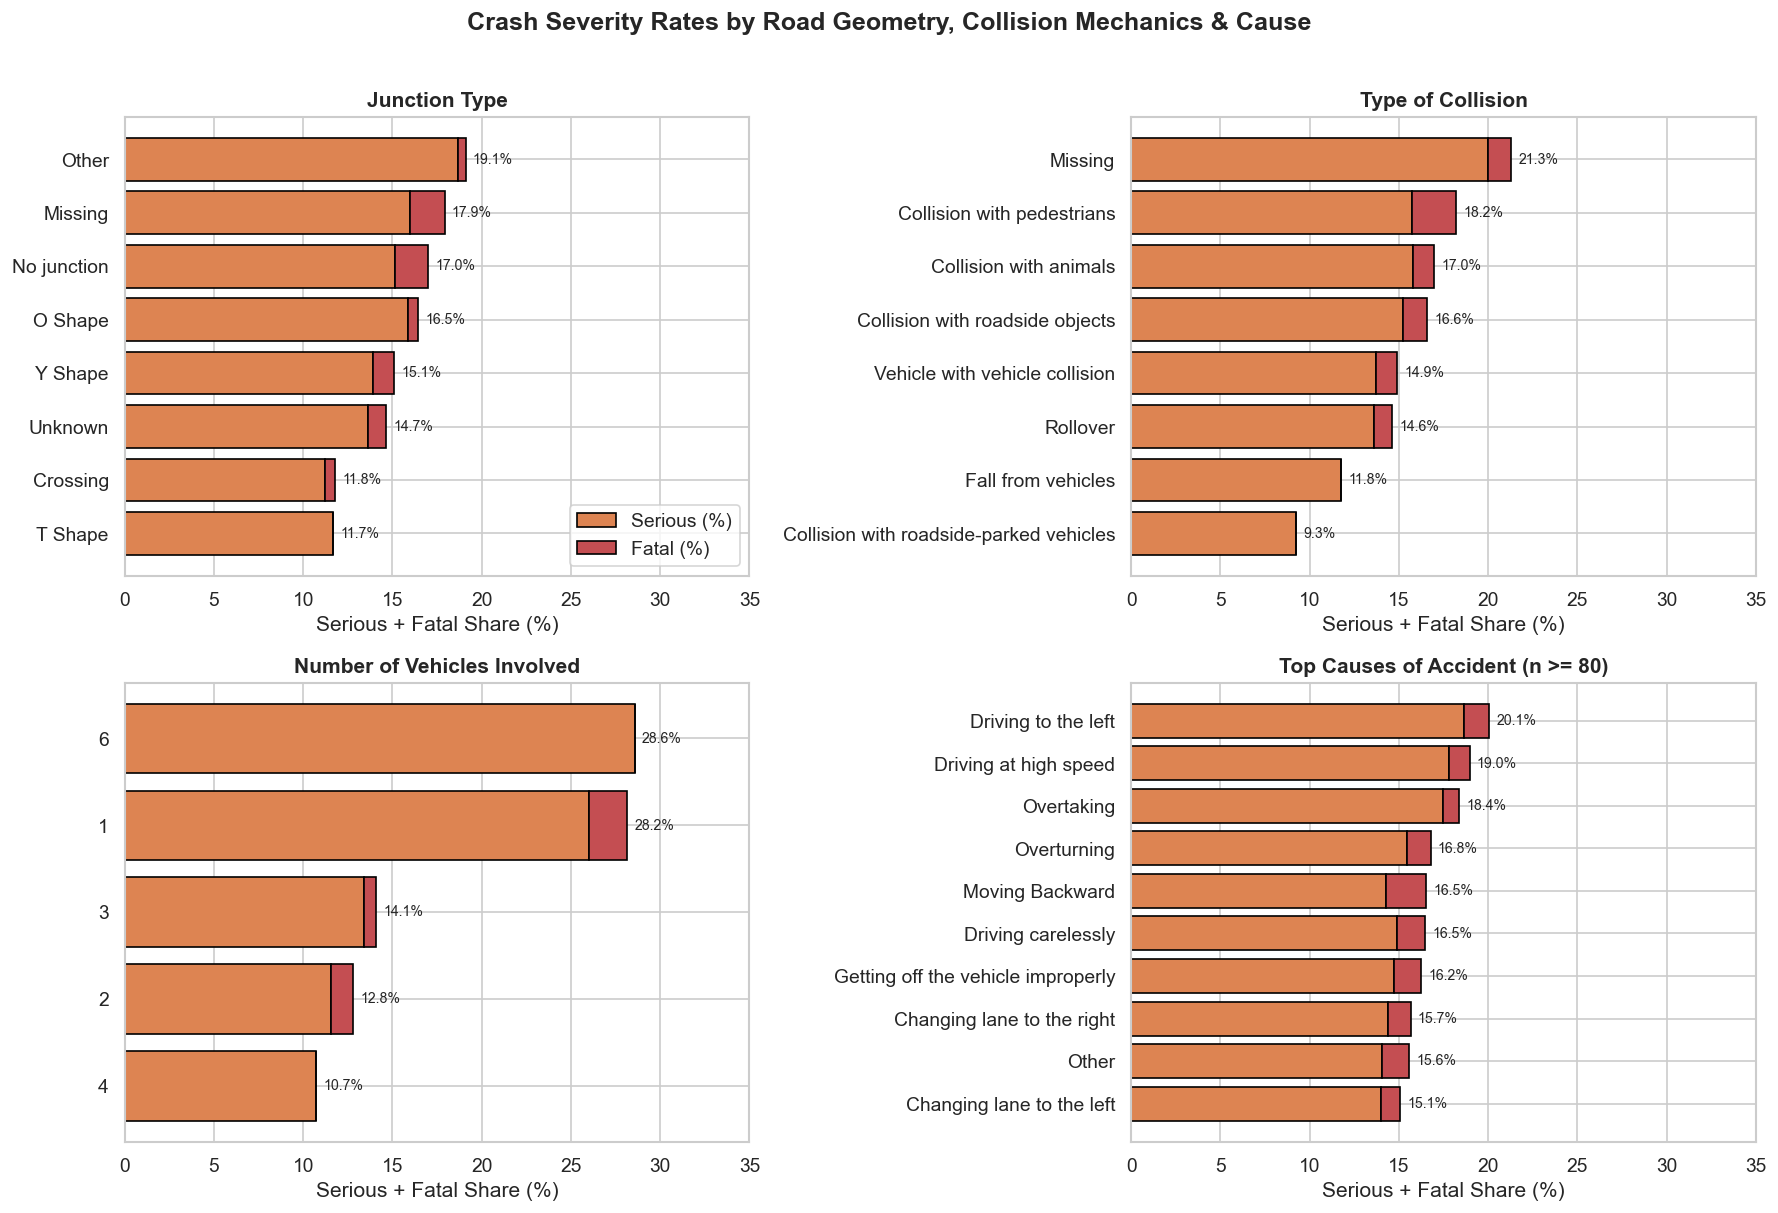

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.ravel()

circumstance_specs = [
    ("Types_of_Junction", 30, "Junction Type"),
    ("Type_of_collision", 30, "Type of Collision"),
    ("Number_of_vehicles_involved", 10, "Number of Vehicles Involved"),
    ("Cause_of_accident", 80, "Top Causes of Accident (n >= 80)"),
]

for ax, (col, min_n, title) in zip(axes, circumstance_specs):
    ct = pd.crosstab(eda_df[col].fillna("Missing"), eda_df[TARGET_COL])[SEVERITY_ORDER]
    ct = ct[ct.sum(axis=1) >= min_n]
    ct_pct = ct.div(ct.sum(axis=1), axis=0) * 100
    ct_pct["Severe_Plus_Fatal"] = ct_pct["Serious Injury"] + ct_pct["Fatal injury"]
    ct_pct = ct_pct.sort_values("Severe_Plus_Fatal", ascending=True).tail(10)

    y_labels = [str(x) for x in ct_pct.index]
    ax.barh(y_labels, ct_pct["Serious Injury"], color="#DD8452", edgecolor="black", label="Serious (%)")
    ax.barh(
        y_labels, ct_pct["Fatal injury"],
        left=ct_pct["Serious Injury"], color="#C44E52", edgecolor="black", label="Fatal (%)"
    )
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Serious + Fatal Share (%)")
    ax.set_xlim(0, max(35, ct_pct["Severe_Plus_Fatal"].max() * 1.2))

    for idx_pos, (_, row) in enumerate(ct_pct.iterrows()):
        total_sf = row["Severe_Plus_Fatal"]
        ax.text(total_sf + 0.4, idx_pos, f"{total_sf:.1f}%", va="center", fontsize=8.5)

axes[0].legend(loc="lower right")
plt.suptitle("Crash Severity Rates by Road Geometry, Collision Mechanics & Cause", fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / "01_circumstances_severity.png", bbox_inches="tight")
plt.show()

**Crash Circumstance Insights:**  
- **Number of Vehicles Involved**: Single-vehicle crashes (`1` vehicle—often pedestrian impacts, rollovers, or fixed-object impacts) have a **much higher Severe + Fatal rate (~28%)** than multi-vehicle collisions (`2+` vehicles, where low-speed urban bumper-to-bumper collisions dominate).
- **Junctions & Collisions**: Specific junction layouts (such as `X Shape` / `Crossing` / `No junction` open stretches) and collision types (`Collision with pedestrians`, `Rollover`) carry markedly higher severe injury rates.

---
## 7. Statistical Evaluation Check: Chi-Square ($\chi^2$) & Cramér's V Feature Association
To complement visual inspection with a formal statistical test, we run Pearson's **Chi-Square ($\chi^2$) test of independence** and compute **Cramér's V** effect size between every pre-crash predictor (including engineered `Hour`) and the 3-class `Accident_severity` target:
$$V = \sqrt{\frac{\chi^2}{n \cdot \min(r - 1, c - 1)}}$$

Features statistically associated with Accident_severity (p < 0.05): 8 / 24



,Feature,Chi2_Statistic,DoF,p_value,Significant_at_0.05,Cramers_V
0,Number_of_vehicles_involved,317.55,10,3.013343e-62,True,0.1135
1,Hour,176.69,46,3.314056e-17,True,0.0847
2,Age_band_of_driver,60.53,8,3.673673e-10,True,0.0496
3,Types_of_Junction,58.94,16,7.877598e-07,True,0.0489
4,Cause_of_accident,49.08,38,1.075290e-01,False,0.0446
5,Day_of_week,47.20,12,4.300319e-06,True,0.0438
6,Type_of_vehicle,46.93,34,6.909269e-02,False,0.0436
7,Light_conditions,45.02,6,4.627954e-08,True,0.0428
8,Area_accident_occured,42.75,24,1.062184e-02,True,0.0417
9,Weather_conditions,41.75,16,4.296262e-04,True,0.0412


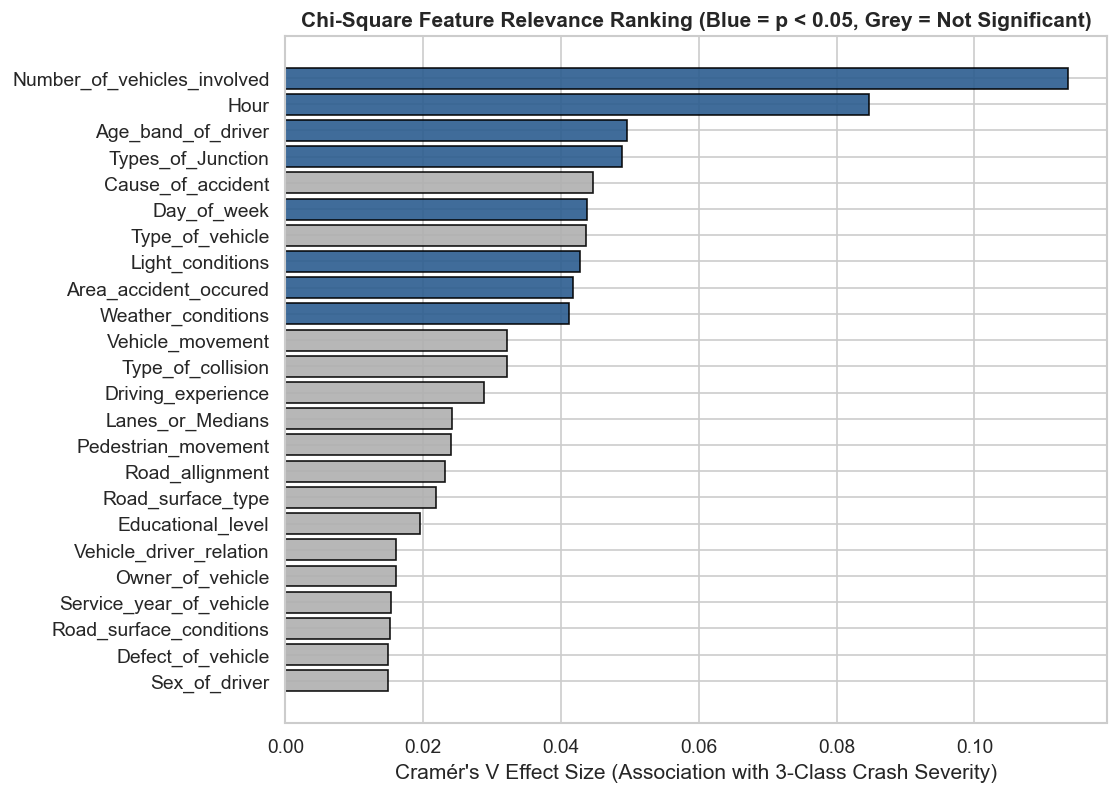

In [9]:
chi2_results = []
test_cols = [c for c in eda_df.columns if c not in [TARGET_COL, "crash_event_id", "Time", "Is_Severe_or_Fatal"]]

for col in test_cols:
    # Fill temporary NaNs with 'Missing' so every row is included in the contingency table
    table = pd.crosstab(eda_df[col].fillna("Missing"), eda_df[TARGET_COL])
    chi2_stat, p_val, dof, _ = chi2_contingency(table)
    n = table.values.sum()
    min_dim = min(table.shape[0] - 1, table.shape[1] - 1)
    cramers_v = np.sqrt(chi2_stat / (n * min_dim)) if min_dim > 0 else 0.0

    chi2_results.append({
        "Feature": col,
        "Chi2_Statistic": round(chi2_stat, 2),
        "DoF": dof,
        "p_value": p_val,
        "Significant_at_0.05": p_val < 0.05,
        "Cramers_V": round(cramers_v, 4),
    })

chi2_df = pd.DataFrame(chi2_results).sort_values("Cramers_V", ascending=False).reset_index(drop=True)
chi2_df.to_csv(TAB_DIR / "01_chi2_feature_relevance.csv", index=False)
print(f"Features statistically associated with Accident_severity (p < 0.05): {chi2_df['Significant_at_0.05'].sum()} / {len(chi2_df)}\n")
display(chi2_df)

# Visualize Cramér's V ranking
plot_chi = chi2_df.sort_values("Cramers_V", ascending=True)
fig, ax = plt.subplots(figsize=(9.5, 6.8))
colors_v = np.where(plot_chi["Significant_at_0.05"], "#2B5C8F", "#B0B0B0")
ax.barh(plot_chi["Feature"], plot_chi["Cramers_V"], color=colors_v, edgecolor="black", alpha=0.9)
ax.set_xlabel("Cramér's V Effect Size (Association with 3-Class Crash Severity)")
ax.set_title("Chi-Square Feature Relevance Ranking (Blue = p < 0.05, Grey = Not Significant)", fontweight="bold")

plt.tight_layout()
plt.savefig(FIG_DIR / "01_chi2_feature_ranking.png", bbox_inches="tight")
plt.show()

**Statistical Test Interpretation:**  
- **8 of the 24 pre-crash predictors** (`Number_of_vehicles_involved`, `Hour`, `Age_band_of_driver`, `Types_of_Junction`, `Day_of_week`, `Light_conditions`, `Area_accident_occured`, and `Weather_conditions`) show statistically significant individual associations ($p < 0.05$) with crash severity.
- Notice that individual Cramér's V values are modest (`< 0.12`), confirming a core premise of Chapter 2: **no single variable determines crash severity on its own**—instead, non-linear *interactions* (such as night-time + unlit road + single-vehicle/pedestrian impact) drive severe outcomes, justifying tree ensembles and neural networks over simple single-variable rules.

---
## 8. Save Cleaned Dataset & Phase Summary
Finally, we save the cleaned, leakage-free dataset (with `crash_event_id` attached) to `data/processed/rta_cleaned.csv` for Notebook 02.

In [10]:
clean_out_path = PROC_DIR / "rta_cleaned.csv"
df_clean.to_csv(clean_out_path, index=False)

print(f"Saved cleaned dataset to: {clean_out_path}")
print(f"Final shape: {df_clean.shape[0]:,} rows x {df_clean.shape[1]} columns (24 predictors + target + crash_event_id)")

Saved cleaned dataset to: /Users/israel/Documents/Projects/accident_severity_model_prediction/data/processed/rta_cleaned.csv
Final shape: 12,316 rows x 26 columns (24 predictors + target + crash_event_id)


### Summary of Notebook 01 Takeaways
1. **Verified Dataset**: 12,316 records across 32 original columns with zero duplicates and severe class imbalance (`84.56%` Slight, `14.15%` Serious, `1.28%` Fatal).
2. **Leakage Eliminated**: All 7 post-crash casualty attributes were removed, leaving 24 legitimate pre-/at-crash predictors.
3. **Clean Text & Safe Missingness Handling**: Text encoding glitches were repaired, and >30% missing columns (`Defect_of_vehicle`, `Service_year_of_vehicle`) were preserved using an explicit `'Unknown'` category rather than discarding ~40% of records.
4. **Event-Level Leakage Guard**: Assigned `crash_event_id` after discovering that 50.5% of adjacent records represent multi-vehicle entries of the same crash timestamp.
5. **EDA & Statistical Evidence**: Both visual patterns and $\chi^2$ tests confirm strong temporal, lighting, junction, collision-type, and vehicle-count signals, while small individual Cramér's V values motivate multi-feature machine learning models in Notebooks 02 and 03.